In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

df = pd.read_csv(r"C:\Users\User\Documents\Kenya_Market_Prices\data\food-prices-kenya.csv")

df.head()
df.columns

Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [3]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [4]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1130,2019-05-15,Rift Valley,Baringo,Marigat,Maize,Retail,KG,52.00,0.52
757,2006-09-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,29.00,0.40
310,2017-02-15,Rift Valley,Baringo,Marigat,Beans,Retail,KG,112.00,1.08
1855,2011-01-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,4730.00,58.59
2326,2017-09-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,4800.00,46.60
878,2016-12-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,77.00,0.75
745,2019-09-15,Eastern,Kitui,Kitui,Maize,Retail,KG,43.30,0.42
479,2016-06-15,Rift Valley,Kajiado,Kajiado,Maize,Retail,KG,45.00,0.44
94,2018-01-15,Coast,Kilifi,Kilifi,Beans,Retail,KG,112.60,1.09
165,2009-12-15,Eastern,Kitui,Kitui,Beans,Retail,KG,60.00,0.80


In [5]:
#turn the date column into real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(5, random_state=42)

859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
Name: date, dtype: datetime64[us]

In [6]:
# add year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

In [7]:
df.head(20)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.30,0.96,2015,1
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.90,0.90,2015,2
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.20,0.89,2015,3
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.00,0.91,2015,4
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.00,0.94,2015,5
5,2015-06-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,95.00,0.98,2015,6
6,2015-07-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,96.00,0.94,2015,7
7,2015-08-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,91.00,0.89,2015,8
8,2015-09-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,94.00,0.89,2015,9
9,2015-10-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,96.00,0.93,2015,10


In [8]:
#fill the missing county and region for the market that has none.
df["county"].isna().sum()
df["region"].isna().sum()
df

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5
...,...,...,...,...,...,...,...,...,...,...,...
2737,2019-08-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,3600.0,34.87,2019,8
2738,2019-09-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,2975.0,28.69,2019,9
2739,2019-10-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,2800.0,27.01,2019,10
2740,2019-11-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,2800.0,27.49,2019,11


In [9]:
mask = df["market"] == "<market name>"
df.loc[mask, ["county", "region"]] = ["<county>", "<region>"]

In [10]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

Series([], dtype: int64)


In [13]:
# How many rows, markets and commodities does the file have
# 2742- rows
df.shape
# Which market has no county, and how many rows does that affect?
# Hola market ,, it affected 59 rows 


(2742, 11)

In [14]:
# what are the first and last dates?
first_date = df["date"].min()
last_date = df["date"].max()
print(first_date)
print(last_date)


2006-01-15 00:00:00
2019-12-15 00:00:00


In [15]:
df.sample(10)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
83,2017-02-15,Coast,Kilifi,Kilifi,Beans,Retail,KG,100.00,0.97,2017,2
874,2016-08-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,69.00,0.68,2016,8
786,2009-02-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,43.00,0.54,2009,2
2707,2017-02-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,3110.00,30.05,2017,2
170,2010-05-15,Eastern,Kitui,Kitui,Beans,Retail,KG,45.00,0.57,2010,5
2068,2009-12-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2113.00,28.10,2009,12
904,2019-02-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,64.80,0.65,2019,2
2192,2006-05-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,1720.00,23.99,2006,5
1790,2019-06-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,7483.75,73.50,2019,6
1323,2007-12-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2913.00,46.39,2007,12


In [16]:
# Which units appear for wholesale maize and for retail maize?
df[df["commodity"] == "Maize"].groupby(["price_type", "unit"]).size()
# Answer: wholesale maize is always quoted per 90 KG bag, retail maize always per KG.


price_type  unit 
Retail      KG       955
Wholesale   90 KG    721
dtype: int64

In [17]:
# Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"]/90, df["price_kes"])


In [18]:
# Split the data into wholesale (per 90 KG bag) 
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy().round(2)
df_wholesale.head()

C:\Users\User\AppData\Local\Temp\ipykernel_26172\834862450.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy().round(2)


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.10
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.00
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.72
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.00
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.79


In [19]:
# Split the data into retail (per KG) prices 
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy().round(2)
df_retail.head()

C:\Users\User\AppData\Local\Temp\ipykernel_26172\1963235828.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy().round(2)


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [20]:
# On average, how does the retail price per KG of maize compare with the wholesale price per KG?
wholesale_kg = df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()
retail_kg = df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()
print(f"Wholesale maize: KES {wholesale_kg:.2f} per kg")
print(f"Retail maize:    KES {retail_kg:.2f} per kg")
print(f"Retail is KES {retail_kg - wholesale_kg:.2f} per kg more, about {(retail_kg / wholesale_kg - 1) * 100:.0f}% higher")


Wholesale maize: KES 28.54 per kg


Retail maize:    KES 47.92 per kg
Retail is KES 19.38 per kg more, about 68% higher


In [21]:
df.loc[df["date"] == "2006-01-15"]

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
118,2006-01-15,Eastern,Kitui,Kitui,Beans,Retail,KG,39.0,0.54,2006,1,39.000000
581,2006-01-15,Eastern,Kitui,Kitui,Maize,Retail,KG,17.0,0.24,2006,1,17.000000
749,2006-01-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,26.0,0.36,2006,1,26.000000
915,2006-01-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,30.0,0.42,2006,1,30.000000
1138,2006-01-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,21.0,0.29,2006,1,21.000000
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1467,2006-01-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,4000.0,55.63,2006,1,44.444444
1631,2006-01-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,3246.0,45.15,2006,1,36.066667
1795,2006-01-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,3175.0,44.16,2006,1,35.277778
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.0,16.58,2006,1,13.244444


In [22]:
# Maize prices over the years
# Calculate the average wholesale maize price per bag for each year and the year-on-year change. 

# →
# Which year had the highest average wholesale maize price?
# →
# Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?

df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)
df_maize.head(10)

yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index().round(2)
yearly_avg


C:\Users\User\AppData\Local\Temp\ipykernel_26172\1877577025.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)


,year,price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [23]:
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg

,year,avg_price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [24]:
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg["avg_price_kes"].max()
# yearly_avg.loc[yearly_avg["avg_price_kes"].max(), "year"]
yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax(), "year"]

yearly_avg.head(20)


,year,avg_price_kes,yoy_change_kes
0,2006,1395.04,NaN
1,2007,1207.45,-187.59
2,2008,1906.32,698.87
3,2009,2513.27,606.95
4,2010,1773.95,-739.32
5,2011,3020.22,1246.27
6,2012,3173.78,153.56
7,2013,2962.46,-211.32
8,2014,2993.72,31.26
9,2015,2690.15,-303.57


In [25]:
highest_year = yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax(), "year"]   # 2017
biggest_rise = yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmax(), "year"]  # 2011
biggest_fall = yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmin(), "year"]  # 2018
print(f"Highest average year: {highest_year}")
print(f"Biggest rise: {biggest_rise}, biggest fall: {biggest_fall}")


Highest average year: 2017
Biggest rise: 2011, biggest fall: 2018


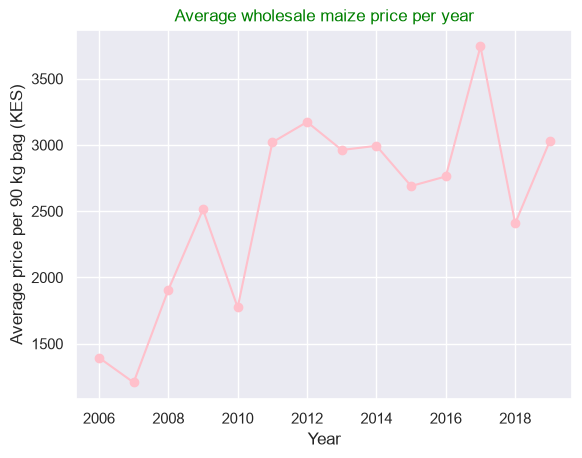

In [26]:
# Plot the yearly average as a line chart with the price in KES on the y-axis.
sns.set_theme()
plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"], color="pink", marker="o")
plt.title("Average wholesale maize price per year", color="green")
plt.xlabel("Year")
plt.ylabel("Average price per 90 kg bag (KES)")
plt.show()


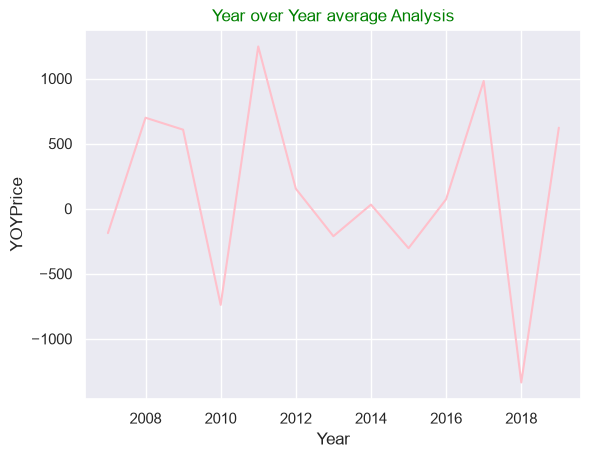

In [27]:
sns.set_theme()
plt.plot(yearly_avg["year"], yearly_avg["yoy_change_kes"], color="pink")
plt.title("Year over Year average Analysis", color = "green")
plt.xlabel("Year")
plt.ylabel("YOYPrice")
plt.show()

In [28]:
# Sell at harvest or hold?
# Average wholesale maize prices by month to find the seasonal pattern. Then compare each market's January and June price, year by year, to see how often storing maize for five months paid off.
monthly_avg = df_maize.groupby("month")["price_kes"].mean().reset_index().round(2)
monthly_avg.columns = ["month", "avg_month_kes"]
monthly_avg.columns
monthly_avg.head(12)

,month,avg_month_kes
0,1,2329.52
1,2,2405.34
2,3,2449.26
3,4,2626.68
4,5,2823.53
5,6,2839.47
6,7,2833.00
7,8,2695.38
8,9,2539.27
9,10,2442.57


In [29]:
# In which month is wholesale maize cheapest on average, and in which is it dearest?
cheapest_month = monthly_avg.loc[monthly_avg["avg_month_kes"].idxmin(), "month"]  # 1 = January
dearest_month = monthly_avg.loc[monthly_avg["avg_month_kes"].idxmax(), "month"]   # 6 = June
print(f"Cheapest month: {cheapest_month}, dearest month: {dearest_month}")


Cheapest month: 1, dearest month: 6


In [30]:
# In what share of market-years was the June price higher than the January price, and what was the median gain?
# What costs and risks of storing maize does this calculation leave out?
# Then compare each market's January and June price, year by year, to see how often storing maize for five months paid off.

# 1. Isolate your January records and your June records separately
jan_data = df_maize[df_maize["month"] == 1][["market", "year", "price_kes"]]

june_data = df_maize[df_maize["month"] == 6][["market", "year", "price_kes"]]

# 2. Merge them side-by-side on the matching Market and Year
# (We use suffixes to clearly label which price belongs to which month)
merged_df = pd.merge(jan_data, june_data, on=["market", "year"], suffixes=("_jan", "_june"))
merged_df
# # 3. Simply subtract the columns directly!
merged_df["gain_kes"] = merged_df["price_kes_june"] - merged_df["price_kes_jan"]
merged_df["profitable"] = merged_df["gain_kes"] > 0

print(merged_df.head(20))

     market  year  price_kes_jan  price_kes_june  gain_kes  profitable
0   Eldoret  2006         1192.0         1549.00    357.00        True
1   Eldoret  2007          947.5         1204.71    257.21        True
2   Eldoret  2008         1200.0         1776.00    576.00        True
3   Eldoret  2009         1743.0         2776.00   1033.00        True
4   Eldoret  2010         2142.0         1556.00   -586.00       False
5   Eldoret  2011         1390.0         3800.00   2410.00        True
6   Eldoret  2012         2800.0         2960.00    160.00        True
7   Eldoret  2013         2642.0         2710.00     68.00        True
8   Eldoret  2014         2794.0         3100.00    306.00        True
9   Eldoret  2015         2000.0         2550.00    550.00        True
10  Eldoret  2016         2210.0         2600.00    390.00        True
11  Eldoret  2017         2780.0         4320.00   1540.00        True
12  Eldoret  2018         2485.0         2030.00   -455.00       False
13  El

In [31]:
# 1. Calculate the share of market-years where the June price was higher than January
total_combinations = len(merged_df)
total_combinations
profitable_combinations = merged_df["profitable"].sum()
profitable_combinations
share_profitable = (profitable_combinations / total_combinations) * 100
share_profitable
# 2. Calculate the median gain
median_gain = merged_df["gain_kes"].median()
median_gain
print(f"Total Market-Years Analyzed: {total_combinations}")
print(f"Share of profitable market-years: {share_profitable:.2f}%")
print(f"Median Gain: KES {median_gain:.2f} per bag")


Total Market-Years Analyzed: 60
Share of profitable market-years: 73.33%
Median Gain: KES 356.00 per bag


### What costs and risks of storing maize does this calculation leave out?

The January-to-June comparison uses market prices only. It leaves out:

- **Storage losses**: weevils, the larger grain borer, rodents, moisture and mould. **Aflatoxin** can make maize unsellable.
- **Weight loss** as the grain dries out in store.
- **Storage costs**: bags (hermetic bags), chemicals, a store or silo, and transport to market.
- **The cost of waiting**: the farmer may need cash at harvest for school fees, debts or inputs, and may have to borrow at interest.
- **Theft.**
- **Price risk**: government actions (NCPB buying prices, duty-free imports) and good harvests in the region can push June prices down. In 1 in 4 market-years June was cheaper than January.
- **Farm-gate vs market prices**: these are wholesale market prices, but farmers usually sell to traders for less.


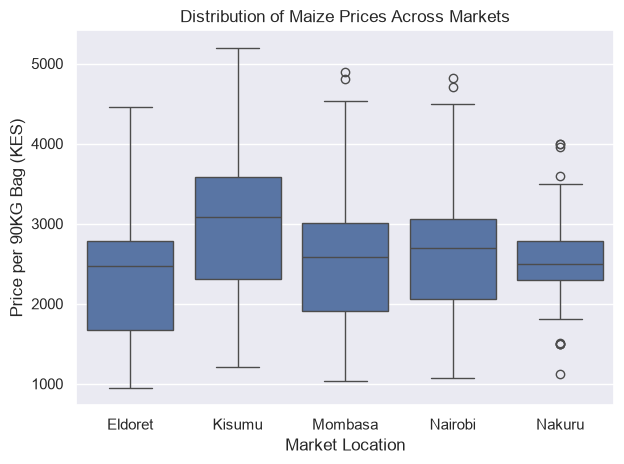

In [32]:
sns.boxplot(data=df_maize, x="market", y="price_kes")
# 2. Add the clean descriptive text layers
plt.title("Distribution of Maize Prices Across Markets")
plt.xlabel("Market Location")
plt.ylabel("Price per 90KG Bag (KES)")

# 3. Clean and display
plt.tight_layout()

In [33]:
df_maize["price_kes"].describe()

count     721.000000
mean     2568.807351
std       849.836482
min       944.210000
25%      1989.000000
50%      2605.000000
75%      3100.000000
max      5200.000000
Name: price_kes, dtype: float64

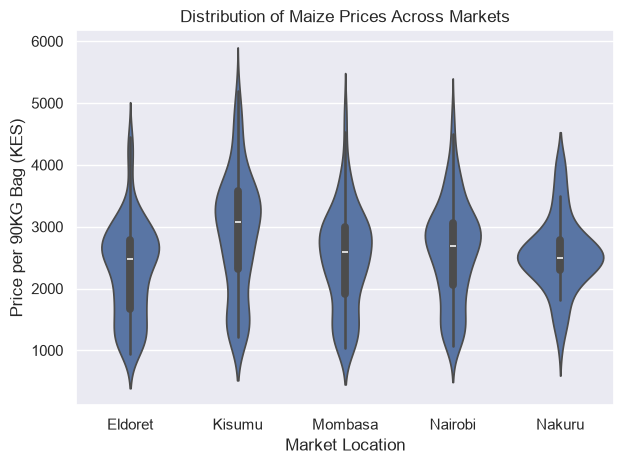

In [34]:

sns.violinplot(data=df_maize, x="market", y="price_kes")
# 2. Add the clean descriptive text layers
plt.title("Distribution of Maize Prices Across Markets")
plt.xlabel("Market Location")
plt.ylabel("Price per 90KG Bag (KES)")

# 3. Clean and display
plt.tight_layout()
plt.show()

In [35]:
# 1. Filter for Retail Maize between 2015 and 2019
df_retail_maize = df[
    (df["commodity"].str.lower() == "maize") & 
    (df["price_type"].str.lower() == "retail") & 
    (df["year"].between(2015, 2019))
].copy()

# 2. Get the Overall Average (2015-2019 combined) to find the absolute cheapest/most expensive
overall_avg = df_retail_maize.groupby("market")["price_kes"].mean().sort_values(ascending=False).reset_index()
overall_avg
print("--- OVERALL AVERAGE PRICES (2015-2019) ---")
print(overall_avg.round(2))

# 3. Get the Yearly Averages and Rank them within each year
yearly_market_avg = df_retail_maize.groupby(["year", "market"])["price_kes"].mean().reset_index()

# Create a ranking column where 1 is the most expensive market for that specific year
yearly_market_avg["rank"] = yearly_market_avg.groupby("year")["price_kes"].rank(ascending=False, method="min")

# 4. View the rankings side-by-side
rankings_pivot = yearly_market_avg.pivot(index="market", columns="year", values="rank")
print("\n--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---")
print(rankings_pivot)

--- OVERALL AVERAGE PRICES (2015-2019) ---
     market  price_kes
0    Lodwar      75.85
1   Mandera      67.53
2   Garissa      59.73
3   Kajiado      50.88
4      Hola      49.87
5  Marsabit      47.50
6   Marigat      46.53
7    Kilifi      43.84
8     Kitui      36.19

--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---
year      2015  2016  2017  2018  2019
market                                
Garissa    3.0   3.0   4.0   3.0   2.0
Hola       7.0   4.0   5.0   4.0   4.0
Kajiado    5.0   5.0   3.0   5.0   5.0
Kilifi     8.0   8.0   7.0   7.0   8.0
Kitui      9.0   9.0   9.0   9.0   9.0
Lodwar     1.0   1.0   1.0   1.0   3.0
Mandera    2.0   2.0   2.0   2.0   1.0
Marigat    6.0   7.0   6.0   8.0   6.0
Marsabit   4.0   6.0   8.0   6.0   7.0


In [36]:
# Which markets ranked in the top three every single year?
top3_every_year = rankings_pivot[(rankings_pivot <= 3).all(axis=1)].index.tolist()
print("Most expensive market:", overall_avg.iloc[0]["market"])
print("Cheapest market:", overall_avg.iloc[-1]["market"])
print("Top three every year:", top3_every_year)


Most expensive market: Lodwar
Cheapest market: Kitui
Top three every year: ['Lodwar', 'Mandera']


### Answers: where households pay most (retail maize, 2015-2019)

- **Most expensive on average:** Lodwar, KES 75.85 per kg.
- **Cheapest on average:** Kitui, KES 36.19 per kg. Households in Lodwar paid about twice as much as households in Kitui.
- **Top three every year:** **Lodwar** and **Mandera**. Garissa came close but fell to 4th in 2017.

The note for Pamoja is in [PAMOJA_NOTE.md](PAMOJA_NOTE.md).

*Data: World Food Programme (WFP), via the Humanitarian Data Exchange (HDX).*
